Theory False-Alarm Rate: 0.27% | Simulated (10k): 0.27%
X-bar detected shift at batch: 131
CUSUM detected shift at batch: 132

SQL Query 1: [(1, 'CNC-Line-A', 10.022960000000001, 0.08789999999999942), (2, 'CNC-Line-A', 10.02186, 0.10250000000000092), (3, 'CNC-Line-A', 9.95432, 0.09570000000000078)]

SQL Query 2: [(1, 100, 10.000374, 0.11415000000000002)]

SQL Query 3: [(1, 10.023, 10.023), (2, 10.0219, 10.02245), (3, 9.9543, 9.999733333333333)]

SQL Query 4: [('CUSUM', 69, 132), ('X-bar', 23, 131)]

SQL Query 5: [(100, 0, 0.0)]


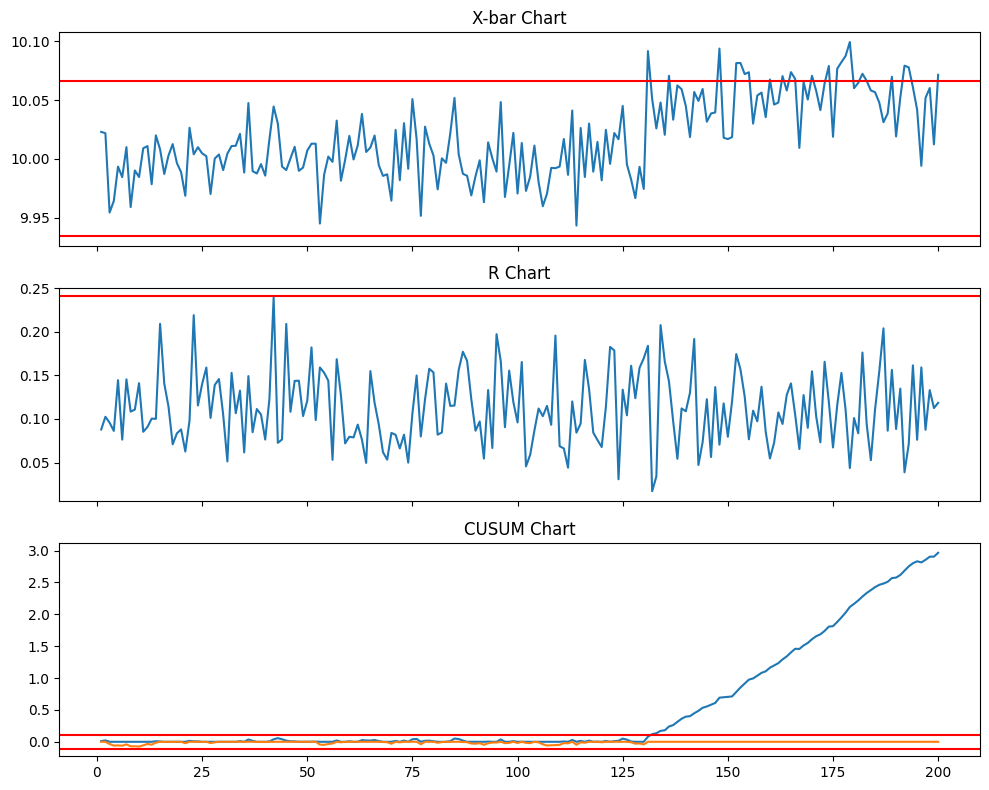

In [1]:
import os, csv, math, random, sqlite3
from collections import deque
import numpy as np
import matplotlib.pyplot as plt

os.makedirs("data", exist_ok=True)
os.makedirs("sql", exist_ok=True)
os.makedirs("reports", exist_ok=True)
random.seed(42)
np.random.seed(42)

# 0. WRITE SQL FILES AUTOMATICALLY (So you can download them for GitHub!)
schema_sql = """
CREATE TABLE Production_Lines (line_id INTEGER PRIMARY KEY, line_name TEXT, target_value REAL);
CREATE TABLE Sample_Batches (batch_id INTEGER PRIMARY KEY, line_id INTEGER, recorded_time TEXT, is_baseline INTEGER, batch_mean REAL, batch_range REAL);
CREATE TABLE Measurements (measurement_id INTEGER PRIMARY KEY, batch_id INTEGER, measured_value REAL);
CREATE TABLE Control_Limits (limit_id INTEGER PRIMARY KEY, line_id INTEGER, chart_type TEXT, ucl REAL, center_line REAL, lcl REAL);
CREATE TABLE Control_Alerts (alert_id INTEGER PRIMARY KEY, batch_id INTEGER, chart_type TEXT, reason TEXT);
"""
open("sql/schema.sql", "w").write(schema_sql.strip())

queries_sql = """
SELECT b.batch_id, l.line_name, AVG(m.measured_value) AS x_bar, MAX(m.measured_value) - MIN(m.measured_value) AS batch_range
FROM Sample_Batches b JOIN Production_Lines l ON b.line_id = l.line_id JOIN Measurements m ON b.batch_id = m.batch_id GROUP BY b.batch_id, l.line_name;

SELECT line_id, COUNT(batch_id) AS total_batches, AVG(batch_mean) AS grand_mean, AVG(batch_range) AS avg_range
FROM Sample_Batches WHERE is_baseline = 1 GROUP BY line_id;

SELECT batch_id, batch_mean, AVG(batch_mean) OVER (ORDER BY batch_id ROWS 4 PRECEDING) AS rolling_avg FROM Sample_Batches;

SELECT a.chart_type, COUNT(a.alert_id) AS total_alerts, MIN(b.batch_id) AS first_alert_batch
FROM Control_Alerts a JOIN Sample_Batches b ON a.batch_id = b.batch_id GROUP BY a.chart_type;

SELECT COUNT(b.batch_id) AS baseline_batches, SUM(CASE WHEN b.batch_mean > c.ucl OR b.batch_mean < c.lcl THEN 1 ELSE 0 END) AS false_alarms,
ROUND(100.0 * SUM(CASE WHEN b.batch_mean > c.ucl OR b.batch_mean < c.lcl THEN 1 ELSE 0 END) / COUNT(b.batch_id), 2) AS false_alarm_pct
FROM Sample_Batches b JOIN Control_Limits c ON b.line_id = c.line_id WHERE b.is_baseline = 1 AND c.chart_type = 'X-bar';
"""
open("sql/analytical_queries.sql", "w").write(queries_sql.strip())

# 1. GENERATE MESSY DATA & CLEAN IT
raw_rows = []
m_id = 1
for b_id in range(1, 201):
    is_base = 1 if b_id <= 100 else 0
    shift = 0.0 if b_id <= 130 else 0.05  # +1.0 sigma shift at batch 131
    for _ in range(5):
        raw_rows.append([m_id, b_id, is_base, round(np.random.normal(10.0 + shift, 0.05), 4)])
        m_id += 1

raw_rows[12][3] = ""      # Missing reading
raw_rows[88][3] = 99.99   # Extreme typo
raw_rows.append(raw_rows[10])  # Duplicate

with open("data/raw_measurements.csv", "w", newline="") as f:
    csv.writer(f).writerows([["measurement_id", "batch_id", "is_baseline", "measured_value"]] + raw_rows)

seen, clean_rows = set(), []
for r in raw_rows:
    if r[0] in seen: continue
    seen.add(r[0])
    val = 10.0 if (r[3] == "" or float(r[3]) > 15 or float(r[3]) < 5) else float(r[3])
    clean_rows.append([r[0], r[1], r[2], val])

with open("data/clean_measurements.csv", "w", newline="") as f:
    csv.writer(f).writerows([["measurement_id", "batch_id", "is_baseline", "measured_value"]] + clean_rows)

# 2. CREATE DATABASE & INSERT DATA
if os.path.exists("data/quality_control.db"): os.remove("data/quality_control.db")
conn = sqlite3.connect("data/quality_control.db")
cur = conn.cursor()
cur.executescript(schema_sql)
cur.execute("INSERT INTO Production_Lines VALUES (1, 'CNC-Line-A', 10.0)")

batches = {}
for m_id, b_id, is_base, val in clean_rows:
    batches.setdefault(b_id, {"is_base": is_base, "vals": []})["vals"].append(val)

for b_id, info in batches.items():
    x_bar = round(float(np.mean(info["vals"])), 4)
    r_val = round(float(np.max(info["vals"]) - np.min(info["vals"])), 4)
    cur.execute("INSERT INTO Sample_Batches VALUES (?, 1, ?, ?, ?, ?)",
                (b_id, f"2026-11-23 08:{b_id%60:02d}", info["is_base"], x_bar, r_val))

cur.executemany("INSERT INTO Measurements VALUES (?, ?, ?)", [(r[0], r[1], r[3]) for r in clean_rows])

# 3. CONTROL LIMITS & CUSUM
x_dbar = np.mean([np.mean(batches[b]["vals"]) for b in range(1, 101)])
r_bar = np.mean([np.max(batches[b]["vals"]) - np.min(batches[b]["vals"]) for b in range(1, 101)])
se = (r_bar / 2.326) / math.sqrt(5)

ucl_x, lcl_x = round(x_dbar + 0.577 * r_bar, 4), round(x_dbar - 0.577 * r_bar, 4)
ucl_r, lcl_r = round(2.114 * r_bar, 4), 0.0
k, h = 0.5 * se, round(5.0 * se, 4)

cur.executemany("INSERT INTO Control_Limits VALUES (?, 1, ?, ?, ?, ?)", [
    (1, "X-bar", ucl_x, round(x_dbar, 4), lcl_x),
    (2, "R-chart", ucl_r, round(r_bar, 4), lcl_r),
    (3, "CUSUM", h, 0.0, -h)
])

# 4. SLIDING WINDOW (deque) & DETECTION
window = deque(maxlen=5)
c_plus, c_minus, c_plus_list, c_minus_list = 0.0, 0.0, [], []
x_alerts, c_alerts, a_id = [], [], 1

for b_id in range(1, 201):
    xb = float(np.mean(batches[b_id]["vals"]))
    window.append(xb)
    if xb > ucl_x or xb < lcl_x:
        x_alerts.append(b_id)
        cur.execute("INSERT INTO Control_Alerts VALUES (?, ?, 'X-bar', '3-sigma breach')", (a_id, b_id))
        a_id += 1
    c_plus = max(0.0, c_plus + (xb - x_dbar) - k)
    c_minus = max(0.0, c_minus - (xb - x_dbar) - k)
    c_plus_list.append(c_plus)
    c_minus_list.append(-c_minus)
    if c_plus > h or c_minus > h:
        c_alerts.append(b_id)
        cur.execute("INSERT INTO Control_Alerts VALUES (?, ?, 'CUSUM', 'CUSUM drift')", (a_id, b_id))
        a_id += 1

conn.commit()

# 5. PRINT RESULTS & SQL OUTPUTS
fa_sim = np.sum(np.abs(np.random.normal(0, 1, 10000)) > 3) / 100
print(f"Theory False-Alarm Rate: 0.27% | Simulated (10k): {fa_sim:.2f}%")
print(f"X-bar detected shift at batch: {next(b for b in x_alerts if b > 130)}")
print(f"CUSUM detected shift at batch: {next(b for b in c_alerts if b > 130)}")

for i, q in enumerate(queries_sql.strip().split(";"), 1):
    if q.strip():
        print(f"\nSQL Query {i}:", cur.execute(q).fetchall()[:3])
conn.close()

# 6. DISPLAY & SAVE CHARTS
fig, ax = plt.subplots(3, 1, figsize=(10, 8), sharex=True)
x_vals = [np.mean(batches[b]["vals"]) for b in range(1, 201)]
r_vals = [np.max(batches[b]["vals"]) - np.min(batches[b]["vals"]) for b in range(1, 201)]

ax[0].plot(range(1, 201), x_vals); ax[0].axhline(ucl_x, color="r"); ax[0].axhline(lcl_x, color="r"); ax[0].set_title("X-bar Chart")
ax[1].plot(range(1, 201), r_vals); ax[1].axhline(ucl_r, color="r"); ax[1].set_title("R Chart")
ax[2].plot(range(1, 201), c_plus_list); ax[2].plot(range(1, 201), c_minus_list); ax[2].axhline(h, color="r"); ax[2].axhline(-h, color="r"); ax[2].set_title("CUSUM Chart")

plt.tight_layout()
plt.savefig("reports/control_charts.png")
plt.show()